<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/notebooks/X1a_reais_algebra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio I (a): a álgebra dos números reais

## Operações, propriedades, o que o computador faz com elas, e a interface que crescerá até os quaternions tridentes

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 1](X1_reais.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/notebooks/X1_reais.ipynb)) · **Próximo:** [X1b_reais_sistemas.ipynb](X1b_reais_sistemas.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/notebooks/X1b_reais_sistemas.ipynb))

**Objetivo.** Rever as regras de conta dos números reais como um **conjunto de axiomas**, ver o que o computador faz com eles (o `float` não obedece a todos), e definir a **interface de domínio** que será reaproveitada nos oito domínios da série.

**Por que começar pelo óbvio.** Cada domínio seguinte perde alguma propriedade que os reais têm, e é exatamente essa perda que obriga a mudar os algoritmos:
- os vetores de ℝ² não sabem se multiplicar entre si;
- os números duais têm um elemento não nulo cujo quadrado é zero;
- os complexos não têm ordem;
- os quaternions não comutam.

Para perceber o que se perdeu, é preciso primeiro listar o que se tinha.

**Roteiro**
1. Os axiomas de corpo, e o que cada domínio da série conserva
2. Três maneiras de representar um real em Python: `float`, `Fraction` e `sympy`
3. O que o `float` quebra: associatividade, distributividade e cancelamento
4. Funções sobre ℝ: a exponencial como ponte entre soma e produto
5. A interface de domínio: compor, inverter, $\mathrm{Exp}$, $\mathrm{Log}$, $\boxplus$ e $\boxminus$
6. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido, dtype=float), np.asarray(esperado, dtype=float)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import sympy as sp
from fractions import Fraction
import math, itertools
rng = np.random.default_rng(1)

---

## 1. Os axiomas de corpo

Os reais, com $+$ e $\times$, formam um **corpo ordenado**. As regras, para quaisquer $a,b,c\in\mathbb R$:

| propriedade | soma | produto |
|---|---|---|
| fechamento | $a+b\in\mathbb R$ | $ab\in\mathbb R$ |
| associatividade | $(a+b)+c=a+(b+c)$ | $(ab)c=a(bc)$ |
| comutatividade | $a+b=b+a$ | $ab=ba$ |
| elemento neutro | $a+0=a$ | $a\cdot1=a$ |
| inverso | $a+(-a)=0$ | $a\cdot a^{-1}=1$, se $a\neq0$ |
| distributividade | $a(b+c)=ab+ac$ | |
| ordem | $a\le b\Rightarrow a+c\le b+c$; $\ a,b\ge0\Rightarrow ab\ge0$ | |

**O que cada domínio da série conserva.** A tabela abaixo é um mapa da série inteira; ela será retomada no nó de cada domínio.

| domínio | estrutura | o que se perde em relação a ℝ |
|---|---|---|
| I · ℝ | corpo ordenado | nada |
| II · ℝ² | espaço vetorial | o produto entre vetores (não há "divisão de vetores") e a ordem |
| III · duais $a+\varepsilon b$, $\varepsilon^2=0$ | anel comutativo | inversos: $\varepsilon\neq0$ e $\varepsilon\cdot\varepsilon=0$ (divisor de zero) |
| IV · ℂ | corpo | a ordem (não existe "$i>0$") |
| V · dual-complexos | anel **não comutativo** | inversos e comutatividade |
| VI · ℍ (quaternions) | anel de divisão | a comutatividade: $ij=-ji$ |
| VII · dual quaternions | anel não comutativo | inversos e comutatividade |
| VIII · quaternions tridentes | anel não comutativo | inversos e comutatividade |

A tabela mostra, de passagem, por que a série precisa do VIII: cada passo **acrescenta** estrutura (rotação, translação, velocidade) ao custo de **perder** propriedades de conta.

---

## 2. Três maneiras de representar um real em Python

Nenhum computador guarda um número real arbitrário: $\sqrt2$ tem infinitos dígitos. Há três compromissos práticos.

| representação | o que guarda | exato? | velocidade |
|---|---|---|---|
| `float` (IEEE 754, 64 bits) | um número da forma $\pm m\cdot2^e$, com 53 bits de mantissa | não: arredonda **toda** conta | rapidíssimo, em hardware |
| `fractions.Fraction` | um racional $p/q$ com inteiros de tamanho arbitrário | sim, para racionais | lento; os inteiros crescem |
| `sympy` | expressões simbólicas: $\sqrt2$, $\pi$, $x$ | sim, inclusive para irracionais e símbolos | muito lento; serve para deduzir, não para simular |

A série usa as três: `sympy` para **deduzir** fórmulas e conferir identidades, `Fraction` quando se quer aritmética exata em contas pequenas, e `float` (via NumPy) para **simular**.

In [2]:
x = 0.1
print("0.1 em float é, exatamente, o racional", Fraction(x))
print("                         = ", f"{x:.30f}")
print("0.1 + 0.2 == 0.3 ?", 0.1 + 0.2 == 0.3, "   (0.1 + 0.2 =", repr(0.1 + 0.2), ")")
print("com Fraction:      ", Fraction(1, 10) + Fraction(2, 10) == Fraction(3, 10))
print("com sympy:         ", sp.Rational(1, 10) + sp.Rational(2, 10) == sp.Rational(3, 10))
print()
eps = np.finfo(float).eps
print(f"épsilon de máquina: {eps:.3e} = 2^{int(np.log2(eps))}  (o menor e tal que 1 + e != 1)")
print("1 + eps/2 == 1 ?", 1 + eps / 2 == 1)
print(f"próximo float depois de 1e16: {np.nextafter(1e16, np.inf):.1f}  (os floats ficam espaçados de 2 em 2)")
print(f"maior float: {np.finfo(float).max:.3e};  menor positivo normal: {np.finfo(float).tiny:.3e}")

0.1 em float é, exatamente, o racional 3602879701896397/36028797018963968
                         =  0.100000000000000005551115123126
0.1 + 0.2 == 0.3 ? False    (0.1 + 0.2 = 0.30000000000000004 )
com Fraction:       True
com sympy:          True

épsilon de máquina: 2.220e-16 = 2^-52  (o menor e tal que 1 + e != 1)
1 + eps/2 == 1 ? True
próximo float depois de 1e16: 10000000000000002.0  (os floats ficam espaçados de 2 em 2)
maior float: 1.798e+308;  menor positivo normal: 2.225e-308


**Detalhes.**
- `Fraction(0.1)` mostra o racional **exato** que o `float` guarda. O número 0,1 não tem representação binária finita, como 1/3 não tem representação decimal finita.
- O **épsilon de máquina** $\varepsilon_M\approx2{,}2\times10^{-16}$ é o erro relativo máximo de uma operação: o computador garante $\mathrm{fl}(a\circ b)=(a\circ b)(1+\delta)$, com $|\delta|\le\varepsilon_M/2$. Toda a análise de erros numéricos parte dessa única frase.
- Os floats **não são uniformemente espaçados**: perto de $10^{16}$, o espaço entre floats consecutivos já é 2.

### Os axiomas, conferidos simbolicamente

In [3]:
a, b, cc = sp.symbols("a b c", real=True)
identidades = {
    "associatividade da soma":       (a + b) + cc - (a + (b + cc)),
    "associatividade do produto":    (a * b) * cc - (a * (b * cc)),
    "comutatividade do produto":     a * b - b * a,
    "distributividade":              a * (b + cc) - (a * b + a * cc),
    "inverso multiplicativo":        a * (1 / a) - 1,
}
for nome, expr in identidades.items():
    print(f"{nome:30s} → simplifica para {sp.simplify(expr)}")

associatividade da soma        → simplifica para 0
associatividade do produto     → simplifica para 0
comutatividade do produto      → simplifica para 0
distributividade               → simplifica para 0
inverso multiplicativo         → simplifica para 0


---

## 3. O que o `float` quebra

Cada operação em `float` é exata **a menos de um arredondamento**. Isso basta para que associatividade e distributividade falhem com frequência. A célula abaixo sorteia um milhão de triplas e conta quantas vezes cada lei falha.

In [4]:
N = 1_000_000
A, B, C = rng.standard_normal((3, N))
falhas = {
    "(a+b)+c == a+(b+c)":  np.mean((A + B) + C != A + (B + C)),
    "(ab)c == a(bc)":      np.mean((A * B) * C != A * (B * C)),
    "a(b+c) == ab+ac":     np.mean(A * (B + C) != A * B + A * C),
    "a+b == b+a":          np.mean(A + B != B + A),
    "ab == ba":            np.mean(A * B != B * A),
}
for lei, f in falhas.items():
    print(f"{lei:22s} falha em {100 * f:5.1f}% dos casos")
confere("a comutatividade nunca falha em float", falhas["a+b == b+a"] + falhas["ab == ba"], 0.0)

# curiosidade: com números sorteados uniformemente em [-1, 1), a soma PARECE associativa
U, V, W = rng.uniform(-1, 1, (3, N))
print(f"\ncom uniform(-1, 1): (a+b)+c == a+(b+c) falha em {100 * np.mean((U + V) + W != U + (V + W)):.1f}% dos casos")
print(f"fração desses números que são múltiplos exatos de 2^-52: {100 * np.mean(U * 2.0**52 == np.round(U * 2.0**52)):.0f}%")

(a+b)+c == a+(b+c)     falha em  31.9% dos casos
(ab)c == a(bc)         falha em  34.8% dos casos
a(b+c) == ab+ac        falha em  45.1% dos casos
a+b == b+a             falha em   0.0% dos casos
ab == ba               falha em   0.0% dos casos
OK   a comutatividade nunca falha em float:  diferença máxima = 0.00e+00

com uniform(-1, 1): (a+b)+c == a+(b+c) falha em 0.0% dos casos
fração desses números que são múltiplos exatos de 2^-52: 100%


**Leitura.** A comutatividade sobrevive (a IEEE 754 garante isso: arredondar $a+b$ e $b+a$ dá o mesmo), mas associatividade e distributividade falham em boa parte dos casos. A consequência prática é importante para quem programa: **a ordem das operações muda o resultado**. Um compilador que reordena somas, ou uma soma paralela numa GPU, pode dar resultados ligeiramente diferentes a cada execução.

**A curiosidade do final da célula** é uma armadilha clássica de teste. O gerador de números uniformes produz números numa **grade** de múltiplos de $2^{-52}$ (a última linha da célula confirma). A soma de três números dessa grade cabe sempre nos 53 bits da mantissa e sai **exata**, de modo que a associatividade da soma parece valer sempre. Um teste com dados "bonitos demais" pode esconder um problema que os dados reais revelam.

### Cancelamento catastrófico

O erro de uma subtração é pequeno em relação aos **operandos**, mas pode ser enorme em relação ao **resultado**, quando os operandos são quase iguais. Exemplo clássico: $\dfrac{1-\cos x}{x^2}\to\dfrac12$ quando $x\to0$.

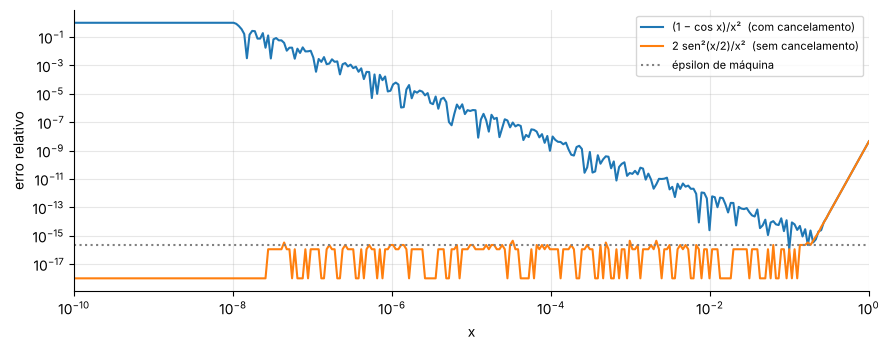

x = 1e-8: ingênua = 0.000000; estável = 0.500000


In [5]:
xs = np.logspace(-10, 0, 300)
ingenua = (1 - np.cos(xs)) / xs**2
estavel = 2 * np.sin(xs / 2)**2 / xs**2          # a mesma função, reescrita sem subtração
xs_s = sp.Symbol("x")
exata = sp.lambdify(xs_s, sp.series((1 - sp.cos(xs_s)) / xs_s**2, xs_s, 0, 10).removeO())(xs)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.loglog(xs, np.abs(ingenua - exata) / exata + 1e-18, label="(1 − cos x)/x²  (com cancelamento)")
ax.loglog(xs, np.abs(estavel - exata) / exata + 1e-18, label="2 sen²(x/2)/x²  (sem cancelamento)")
ax.axhline(np.finfo(float).eps, ls=":", color="gray", label="épsilon de máquina")
ax.set_xlabel("x"); ax.set_ylabel("erro relativo"); ax.legend(fontsize=8); ax.set_xlim(1e-10, 1)
plt.tight_layout(); plt.show()
print(f"x = 1e-8: ingênua = {ingenua[np.argmin(np.abs(xs - 1e-8))]:.6f}; estável = {estavel[np.argmin(np.abs(xs - 1e-8))]:.6f}")

**Leitura.** Para $x$ pequeno, $\cos x$ arredonda para um número muito perto de 1, e a subtração $1-\cos x$ apaga quase todos os dígitos corretos. Para $x<10^{-8}$, a fórmula ingênua dá **zero**, o que é um erro de 100%. Reescrever a fórmula para evitar a subtração resolve o problema.

> **Nota: o mesmo problema volta no filtro de Kalman.** A atualização da covariância $\mathbf P\leftarrow(\mathbf I-\mathbf K\mathbf H)\mathbf P$ é uma subtração disfarçada. Com medidas muito precisas, ela pode produzir uma covariância com autovalores negativos, que não é uma covariância. Por isso a série simetriza $\mathbf P$ depois de cada correção, e as implementações profissionais usam a "forma de Joseph" ou a forma de raiz quadrada.

### Somar muitos números: a soma compensada de Kahan

Somar $0{,}1$ dez milhões de vezes deveria dar $10^6$. Cada soma perde um pouco, e o erro se acumula. A soma de Kahan guarda, numa segunda variável, o que se perdeu em cada passo e devolve na soma seguinte.

In [6]:
def soma_ingenua(v):
    s = 0.0
    for x in v:
        s += x
    return s

def soma_kahan(v):
    s, comp = 0.0, 0.0
    for x in v:
        y = x - comp            # devolve o que se perdeu da última vez
        t = s + y
        comp = (t - s) - y      # o que se perdeu agora (em aritmética exata seria 0)
        s = t
    return s

v = [0.1] * 10_000_000
exato = Fraction(1, 10) * len(v)
for nome, f in [("ingênua", soma_ingenua), ("Kahan", soma_kahan), ("math.fsum (exata)", math.fsum)]:
    s = f(v)
    print(f"{nome:18s} {s:.10f}   erro = {float(Fraction(s) - exato):+.3e}")

ingênua            999999.9998389754   erro = -1.610e-04


Kahan              1000000.0000000000   erro = +0.000e+00
math.fsum (exata)  1000000.0000000000   erro = +0.000e+00


**Leitura.** A soma ingênua erra já na quarta casa depois da vírgula; a de Kahan acerta todos os dígitos, como `math.fsum`, que soma os `float` dados exatamente e só arredonda no fim. (Cada `0.1` é ligeiramente maior que $1/10$, mas a diferença acumulada, uns $5\times10^{-11}$, é menor que a metade do espaço entre floats perto de $10^6$, e some no arredondamento final.)

Integrar uma equação diferencial (etapa c) é somar milhares de pequenos incrementos, e por isso este tipo de erro reaparece lá.

---

## 4. Funções sobre ℝ: a exponencial como ponte entre soma e produto

Uma função $f:\mathbb R\to\mathbb R$ estende as operações a algo "contínuo". De todas, a exponencial é a que reaparece em todos os domínios da série, por três motivos.

1. **Ela transforma soma em produto:** $e^{a+b}=e^ae^b$. É um *homomorfismo* do grupo $(\mathbb R,+)$ no grupo $(\mathbb R_{>0},\times)$, e o logaritmo é o inverso.
2. **Ela resolve a equação diferencial mais simples:** $\dot y=\lambda y\Rightarrow y(t)=e^{\lambda t}y_0$. Nos próximos domínios, a mesma ideia vale com $\lambda$ trocado por uma velocidade angular ou um torsor: "integrar uma velocidade constante" vai ser sempre "tomar uma exponencial".
3. **Ela tem uma série de potências que converge sempre:** $e^x=\sum_k x^k/k!$. A mesma série define a exponencial de uma matriz, de um complexo, de um quaternion e de um quaternion tridente.

In [7]:
x = sp.Symbol("x"); a_, b_ = sp.symbols("a b")
print("série de Taylor de exp:", sp.series(sp.exp(x), x, 0, 7))
print("exp(a+b) − exp(a)·exp(b) =", sp.simplify(sp.exp(a_ + b_) - sp.exp(a_) * sp.exp(b_)))
y = sp.Function("y"); lam, y0, t = sp.symbols("lambda y_0 t")
print("solução de y' = λy:", sp.dsolve(sp.Eq(y(t).diff(t), lam * y(t)), ics={y(0): y0}))

# a série truncada, em float: quantos termos para chegar ao épsilon de máquina?
def exp_serie(x, n):
    termo, s = 1.0, 1.0
    for k in range(1, n):
        termo *= x / k; s += termo
    return s
for xv in [0.5, 5.0, -20.0]:
    n = next(n for n in range(1, 200) if abs(exp_serie(xv, n) - math.exp(xv)) <= 4 * np.finfo(float).eps * math.exp(xv)) \
        if xv > 0 else None
    print(f"x = {xv:6.1f}: série com 60 termos = {exp_serie(xv, 60):.6e};  math.exp = {math.exp(xv):.6e}"
          + (f";  termos necessários: {n}" if n else "  ← a série alterna sinais e cancela: mau método para x negativo"))

série de Taylor de exp: 1 + x + x**2/2 + x**3/6 + x**4/24 + x**5/120 + x**6/720 + O(x**7)
exp(a+b) − exp(a)·exp(b) = 0
solução de y' = λy: Eq(y(t), y_0*exp(lambda*t))
x =    0.5: série com 60 termos = 1.648721e+00;  math.exp = 1.648721e+00;  termos necessários: 14
x =    5.0: série com 60 termos = 1.484132e+02;  math.exp = 1.484132e+02;  termos necessários: 32
x =  -20.0: série com 60 termos = -1.042344e-04;  math.exp = 2.061154e-09  ← a série alterna sinais e cancela: mau método para x negativo


**Leitura.** Para $x=-20$, a série soma termos enormes de sinais alternados (o maior é $20^{20}/20!\approx4\times10^7$) para chegar a $2\times10^{-9}$: é o cancelamento catastrófico da seção 3, e o resultado sai errado, até com o sinal trocado. As bibliotecas calculam $e^{x}$ de outro modo, por exemplo $e^{-20}=1/e^{20}$, ou reduzindo o argumento.

### Derivadas: simbólica, numérica e o dilema do passo

Os filtros de Kalman não lineares (etapa d) precisam de **derivadas** (jacobianos). Há três maneiras de obtê-las:
- **simbólica** (`sympy.diff`): exata, mas a expressão pode crescer muito;
- **numérica** por diferenças finitas: simples, mas com um dilema. Passo grande dá erro de **truncamento** (a reta secante não é a tangente); passo pequeno dá erro de **arredondamento** (o cancelamento da seção 3);
- **automática**: exata e barata. Aparece no domínio III, com os números duais.

derivada simbólica: exp(sin(x))*cos(x)


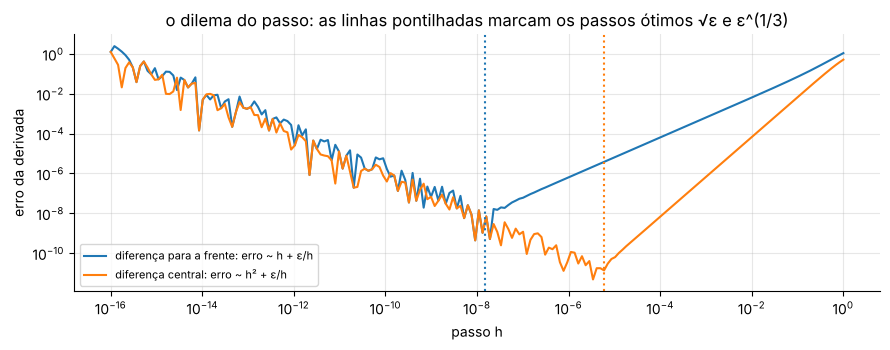

melhor erro, diferença para a frente: 4.4e-10 (h ≈ 9e-09)
melhor erro, diferença central:      4.8e-12 (h ≈ 3e-06)


In [8]:
f = lambda x: np.exp(np.sin(x))
df_exata = lambda x: np.cos(x) * np.exp(np.sin(x))
xs_sym = sp.Symbol("x")
print("derivada simbólica:", sp.diff(sp.exp(sp.sin(xs_sym)), xs_sym))

x0 = 1.0
hs = np.logspace(-16, 0, 200)
e_frente = np.abs((f(x0 + hs) - f(x0)) / hs - df_exata(x0))
e_central = np.abs((f(x0 + hs) - f(x0 - hs)) / (2 * hs) - df_exata(x0))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.loglog(hs, e_frente + 1e-18, label="diferença para a frente: erro ~ h + ε/h")
ax.loglog(hs, e_central + 1e-18, label="diferença central: erro ~ h² + ε/h")
ax.axvline(np.sqrt(np.finfo(float).eps), ls=":", color="tab:blue"); ax.axvline(np.finfo(float).eps**(1/3), ls=":", color="tab:orange")
ax.set_xlabel("passo h"); ax.set_ylabel("erro da derivada"); ax.legend(fontsize=8)
ax.set_title("o dilema do passo: as linhas pontilhadas marcam os passos ótimos √ε e ε^(1/3)")
plt.tight_layout(); plt.show()
print(f"melhor erro, diferença para a frente: {e_frente.min():.1e} (h ≈ {hs[e_frente.argmin()]:.0e})")
print(f"melhor erro, diferença central:      {e_central.min():.1e} (h ≈ {hs[e_central.argmin()]:.0e})")

**Leitura.** O erro desce com $h$ até um ponto ótimo e depois **sobe** de novo, porque o arredondamento domina. A diferença central chega a uns $5\times10^{-12}$, e nenhuma escolha de $h$ faz melhor que isso. A derivação automática (domínio III) e o passo complexo (domínio IV) eliminam esse dilema.

---

## 5. A interface de domínio

Em toda a série, o estado de um objeto em movimento vai viver num "domínio" com seis operações. Em ℝ elas são triviais, e por isso é o lugar certo para defini-las com calma.

| operação | significado físico | em ℝ |
|---|---|---|
| `compoe(g, h)` | fazer um movimento depois do outro | $g+h$ |
| `inverso(g)` | desfazer um movimento | $-g$ |
| `identidade` | não se mover | $0$ |
| `Exp(ξ)` | o movimento obtido mantendo a velocidade $\xi$ por uma unidade de tempo | $\xi$ |
| `Log(g)` | a velocidade constante que produziria o movimento $g$ | $g$ |
| `mais(x, δ)` $=x\boxplus\delta$ | aplicar um pequeno incremento $\delta$ (um vetor) ao estado $x$ | $x+\delta$ |
| `menos(y, x)` $=y\boxminus x$ | o incremento que leva $x$ a $y$ | $y-x$ |

Como se vê, $\boxplus$ é composto de `compoe` e `Exp`: $x\boxplus\delta=$ `compoe(x, Exp(δ))`. É a mesma operação $\boxplus$ dos notebooks 5 e 6 da série Kalman. Nos próximos domínios, a coluna da direita fica cada vez mais interessante:

| domínio | $x\boxplus\delta$ |
|---|---|
| ℝ, ℝ² | $x+\delta$ |
| duais | $(\theta+\delta_\theta)+\varepsilon(d+\delta_d)$ |
| ℂ | $z+\delta$ (posição) ou $z\,e^{i\delta}$ (rotação) |
| dual-complexos | $\hat z\,\mathrm{Exp}(\delta)$ |
| quaternions | $q\otimes\mathrm{Exp}(\delta)$ |
| dual quaternions | $\hat q\otimes\mathrm{Exp}(\delta)$ |
| tridentes | $\tilde q\otimes\mathrm{Exp}(\delta)$ |

O código abaixo define a interface para ℝ e confere os axiomas de **grupo** (associatividade, identidade e inverso) e as relações entre $\mathrm{Exp}$, $\mathrm{Log}$, $\boxplus$ e $\boxminus$. Os mesmos testes, com os mesmos nomes, serão aplicados aos outros sete domínios.

In [9]:
class DominioReal:
    """Domínio I: a reta. Os movimentos são translações; compor é somar."""
    nome = "ℝ"
    dim = 1                                   # dimensão do vetor de incremento δ
    identidade = 0.0
    def compoe(self, g, h): return g + h
    def inverso(self, g):   return -g
    def Exp(self, xi):      return float(xi)
    def Log(self, g):       return float(g)
    def mais(self, x, d):   return self.compoe(x, self.Exp(d))
    def menos(self, y, x):  return self.Log(self.compoe(self.inverso(x), y))

def testa_dominio(D, amostra, tol=1e-12):
    """Os mesmos testes servirão para os oito domínios."""
    g, h, k = amostra(), amostra(), amostra()
    print(f"domínio {D.nome}")
    confere("  associatividade da composição", D.menos(D.compoe(D.compoe(g, h), k), D.compoe(g, D.compoe(h, k))), 0, tol)
    confere("  identidade", D.menos(D.compoe(g, D.identidade), g), 0, tol)
    confere("  inverso", D.menos(D.compoe(g, D.inverso(g)), D.identidade), 0, tol)
    d = D.Log(amostra()) * 0.3
    confere("  Log(Exp(δ)) = δ", D.Log(D.Exp(d)), d, tol)
    confere("  (x ⊞ δ) ⊟ x = δ", D.menos(D.mais(g, d), g), d, tol)
    confere("  x ⊞ (y ⊟ x) = y", D.menos(D.mais(g, D.menos(h, g)), h), 0, tol)

R = DominioReal()
testa_dominio(R, lambda: float(rng.normal(scale=10)))

domínio ℝ
OK     associatividade da composição:  diferença máxima = 1.78e-15
OK     identidade:  diferença máxima = 0.00e+00
OK     inverso:  diferença máxima = 0.00e+00
OK     Log(Exp(δ)) = δ:  diferença máxima = 0.00e+00
OK     (x ⊞ δ) ⊟ x = δ:  diferença máxima = 5.55e-16
OK     x ⊞ (y ⊟ x) = y:  diferença máxima = 1.78e-15


**Para pensar.** Por que a conferência da associatividade usa `menos(...)` em vez de `==`? Porque, como a seção 3 mostrou, $(g+h)+k$ e $g+(h+k)$ **não** são iguais em `float`: são iguais a menos de alguns $\varepsilon_M$. Todas as conferências da série comparam com tolerância.

---

## 6. Exercícios

1. **Densidade dos floats.** Quantos `float` existem entre 1 e 2? E entre $2^{52}$ e $2^{53}$? Confira com `np.nextafter` e explique a resposta pela representação $\pm m\cdot2^e$.
2. **Associatividade com inteiros.** Repita o teste da seção 3 com inteiros grandes do Python (`int`). Alguma lei falha? E com `np.int64`, perto de $2^{63}$?
3. **Variância em uma passada.** A fórmula $\mathrm{Var}=\overline{x^2}-\bar x^2$ sofre cancelamento quando a média é grande em relação ao desvio. Mostre isso com $x_i=10^9+\text{ruído}$ e implemente o algoritmo de Welford, que é estável. (Este é, aliás, um filtro de Kalman disfarçado: veja a seção 1 do notebook 5 da série Kalman.)
4. **Exponencial por redução de argumento.** Implemente $e^x$ usando $e^x=(e^{x/2^k})^{2^k}$: some poucos termos da série para $x/2^k$ pequeno e eleve ao quadrado $k$ vezes. Compare o erro com o da série direta para $x=\pm20$. (A mesma técnica, *scaling and squaring*, calcula a exponencial de matrizes no SciPy.)
5. **sympy contra float.** Calcule $\sum_{k=1}^{10^4}1/k^2$ com `float`, somando do maior para o menor e do menor para o maior, e compare com o valor exato do `sympy` (truncado). Qual ordem é melhor, e por quê?